<a href="https://colab.research.google.com/github/Kushagra14/triton_tutorials/blob/main/GEMM_tutorial.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Mastering GEMM: General Matrix Multiply vs. Textbook Matmul

Mathematically, **Textbook Matmul** and **GEMM** (GEneral Matrix Multiply) compute the same base product. However, they differ significantly in **interface design** (how they represent problems) and **hardware implementation** (how they achieve speed).

---

## 1. The Interface: A Superset of Plain Matmul

While textbook matmul is simply $C = A \cdot B$, the standardized BLAS **GEMM** interface is:
$$
C = \alpha \cdot \text{op}(A) \cdot \text{op}(B) + \beta \cdot C
$$

### Key Parameters Explained:
*   **$\alpha, \beta$ (Scalars):**
    *   If $\alpha = 1$ and $\beta = 0$, this simplifies to plain $A \cdot B$.
    *   Accumulation ($\beta \neq 0$) allows accumulating results directly into an existing output tensor, which is critical for **split-K algorithms**, **residual connections**, and **gradient accumulation**.
*   **$\text{op}(\cdot)$ (In-place Transposition):**
    *   Allows inputs to be processed as-is or transposed on-the-fly. This avoids copying or rearranging data in memory.
    *   This is why backpropagation is computationally cheap: $dX = dY \cdot W^T$ and $dW = X^T \cdot dY$ can use the exact same kernel with different transpose flags.
*   **Strides & Leading Dimensions:** Supports sub-matrices within larger allocations without requiring packed memory layouts.
*   **Mixed Precision:** Allows inputs (e.g., FP8/FP16), accumulation (FP32), and outputs (BF16) to utilize different data types.

---

## 2. The Implementation: Naive vs. Hardware-Optimized

### The Naive 3-Loop Baseline
```python
for i in range(M):
    for j in range(N):
        for k in range(K):
            C[i][j] += A[i][k] * B[k][j]
```
*   **The Problem:** Terrible cache utilization. Column-wise memory reads for $B$ trigger repeated, slow high-latency retrievals from global memory.

### The GEMM Kernel Approach (Up to 100x+ Faster)
1.  **Tiling/Blocking:** Data is partitioned into small tiles so loaded chunks of $A$ and $B$ are reused repeatedly inside fast on-chip memories.
2.  **Memory Hierarchy:** Actively manages data movement: *Global Memory $\rightarrow$ Shared Memory $\rightarrow$ Registers*.
3.  **Hardware Acceleration:** Leverages specialized Tensor Cores or SIMD units instead of scalar arithmetic.
4.  **Pipelining:** Overlaps the asynchronous loading of the next tile with computations on the current tile.
5.  **Fused Epilogues:** Applies operations like bias additions, activation functions (e.g., ReLU), or quantization directly to registers before writing $C$ back to main memory.

---

## 3. Comparison Summary

| Feature | Textbook Matmul | GEMM |
| :--- | :--- | :--- |
| **Formula** | $C = A \cdot B$ | $C = \alpha \cdot \text{op}(A) \cdot \text{op}(B) + \beta \cdot C$ |
| **Transposes** | Manual copy required | Built-in flags (zero-copy) |
| **Accumulation** | No | Yes (via $\beta$) |
| **Memory Layout** | Assumes tightly packed arrays | Strided / sub-matrix support |
| **Execution Structure** | Nested scalar loops | Tiled, pipelined, tensor-core accelerated, fused |

---

## 4. Triton/GPU Execution Flow: Legacy vs. GEMM

In high-performance environments (like Triton), both layouts use tiling and execute within a single kernel. The primary divergence occurs in the **epilogue** (how the final values are written back).

### Standard Tiled Matmul Epilogue
```python
acc = zeros((BLOCK_M, BLOCK_N))
for k in range(0, K, BLOCK_K):
    a = load(A_tile)
    b = load(B_tile)
    acc += dot(a, b)

# Direct store
store(C_tile, acc)
```

### Optimized GEMM Epilogue
```python
# K-loop is finished; acc is still sitting in registers
acc = alpha * acc

if beta != 0:
    c_old = load(C_tile)  # Loaded ONLY at the end, saving bandwidth
    acc = acc + beta * c_old

# Fused operations (e.g., bias, activation, cast to target precision)
acc = apply_fused_ops(acc)

store(C_tile, acc)
```

### Takeaway for Study:
*   **C is loaded at the very end:** The output tile $C$ is not accessed during the main $K$-loop. If $\beta = 0$, the load is skipped entirely.
*   **Zero-copy transpositions:** Handled purely by passing different stride steps (`stride_am`, `stride_ak`) to Triton's pointer arithmetic.

## Deep Dive: Standard Triton Grouped GEMM vs. TMA (Tensor Memory Accelerator) GEMM

Although both kernels in the notebook perform grouped matrix multiplications, they leverage entirely different hardware mechanisms for data movement.

### 1. Standard Grouped GEMM (`grouped_matmul_kernel`)
* **Software-Driven Addressing:** Memory pointers are computed manually in software inside the kernel via code like `a_ptr + offs_am[:, None] * lda + offs_k[None, :]`.
* **Register-Heavy Instructions:** The SM (Streaming Multiprocessor) must actively allocate registers to keep track of multidimensional tensor offsets, calculate memory strides, and issue explicit load (`tl.load`) commands.
* **Hardware Target:** Works on any CUDA-compatible GPU (e.g., Ampere A100, Turing, etc.).

### 2. TMA Grouped GEMM (`grouped_matmul_tma_kernel`)
* **Hardware-Driven Addressing:** Leverages Hopper-generation (H100+) **TMA (Tensor Memory Accelerator)** hardware units.
* **Descriptor-Based Offloading:** Instead of doing pointer arithmetic in software, Triton defines a global multi-dimensional tensor descriptor (`tl.make_tensor_descriptor`).
* **Zero Register Overhead for Addressing:** The SM offloads all spatial address math to the dedicated physical TMA hardware. Instead of complex pointer calculations, the kernel simply issues a coordinate load (`a_desc.load([offs_am, kk * BLOCK_SIZE_K])`).
* **Hardware Target:** Strictly requires Hopper Architecture or newer (NVIDIA Compute Capability 9.0+).

----------------------------
### *What disappears from your code*
- Pointer arithmetic and stride bookkeeping
- Pointer increments inside the loop
- Boundary masks, because the hardware zero-fills out-of-bounds elements
- Per-element address computation


### *What changes underneath*

This is where the speedup comes from:

- Address generation moves to hardware. In the pointer version, every thread computes its own addresses and issues its own loads. With TMA, one thread issues a single bulk request and a dedicated copy engine does the rest.
- The copy is asynchronous. Data moves global → shared memory without passing through registers, and completion is tracked with an mbarrier. The SM can run the MMA on tile k while tile k+1 is in flight.
- Shared memory layout is swizzled by the hardware, so the tiles land in the layout the tensor cores want, without bank conflicts.
Registers and ALU slots are freed, since they are no longer spent on address math and masks.
- It enables warp specialization: a producer warp issues TMA loads while consumer warps run wgmma. This is the Hopper-style structure from earlier.

In [1]:
import time
import numpy as np

# Define matrix dimensions (using relatively small sizes because naive matmul is incredibly slow in Python)
M, N, K = 128, 128, 128

# Initialize random matrices
np.random.seed(42)
A = np.random.rand(M, K).astype(np.float32)
B = np.random.rand(K, N).astype(np.float32)
C_naive = np.zeros((M, N), dtype=np.float32)

print(f"Benchmarking Matrix Multiplication (Size: {M}x{K} by {K}x{N})\n")

# --- 1. Naive 3-Loop Implementation ---
print("Running Naive 3-Loop Matmul in pure Python...")
start_time = time.time()
for i in range(M):
    for j in range(N):
        acc = 0.0
        for k in range(K):
            acc += A[i, k] * B[k, j]
        C_naive[i, j] = acc
naive_duration = time.time() - start_time
print(f"Naive Duration: {naive_duration:.5f} seconds\n")

# --- 2. Tiled / Optimized GEMM (via Optimized BLAS under NumPy) ---
# NumPy uses highly optimized BLAS GEMM internally (which leverages tiling, vectorization, and multi-threading)
print("Running Highly-Optimized GEMM (via NumPy/BLAS)...")
# To make the test fair and clear, let's run it multiple times to average the fast execution
start_time = time.time()
C_gemm = np.matmul(A, B)
gemm_duration = time.time() - start_time
print(f"Optimized GEMM Duration: {gemm_duration:.5f} seconds\n")

# --- 3. Results Verification & Speedup Analysis ---
speedup = naive_duration / gemm_duration if gemm_duration > 0 else float('inf')
print("--- Summary Comparison ---")
print(f"Are the results mathematically identical? {np.allclose(C_naive, C_gemm)}")
print(f"Speedup Factor: {speedup:.1f}x faster using optimized GEMM structure!")

Benchmarking Matrix Multiplication (Size: 128x128 by 128x128)

Running Naive 3-Loop Matmul in pure Python...
Naive Duration: 1.30416 seconds

Running Highly-Optimized GEMM (via NumPy/BLAS)...
Optimized GEMM Duration: 0.00211 seconds

--- Summary Comparison ---
Are the results mathematically identical? True
Speedup Factor: 616.9x faster using optimized GEMM structure!


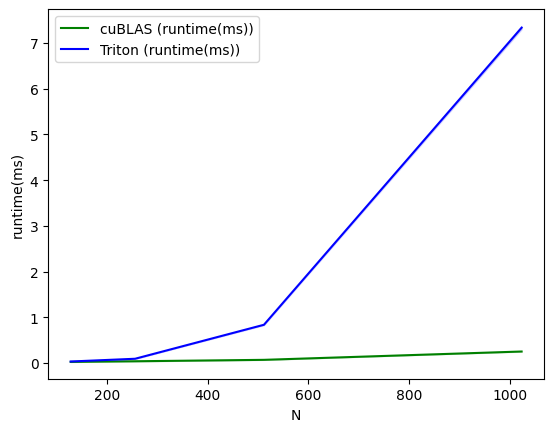

group-gemm-performance:
        N  cuBLAS (runtime(ms))  Triton (runtime(ms))
0   128.0              0.022464              0.031168
1   256.0              0.036576              0.091296
2   512.0              0.067600              0.835104
3  1024.0              0.249856              7.336096


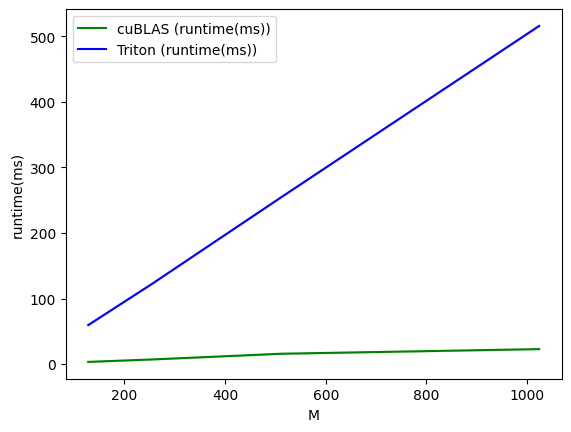

group-gemm-performance-m-8192-k-8192:
        M  cuBLAS (runtime(ms))  Triton (runtime(ms))
0   128.0              3.287072             59.423008
1   256.0              7.024320            122.986237
2   512.0             15.736672            254.814209
3  1024.0             22.798832            515.989746


In [1]:
from typing import Optional
import torch

import triton
import triton.language as tl

DEVICE = triton.runtime.driver.active.get_active_torch_device()


def is_cuda():
    return triton.runtime.driver.active.get_current_target().backend == "cuda"


def supports_tma():
    return is_cuda() and torch.cuda.get_device_capability()[0] >= 9


def num_sms():
    if is_cuda():
        return torch.cuda.get_device_properties("cuda").multi_processor_count
    return 148


@triton.autotune(
    configs=[
        triton.Config({
            'BLOCK_SIZE_M': 128,
            'BLOCK_SIZE_N': 128,
            'BLOCK_SIZE_K': 32,
            'NUM_SM': 84,
        }),
        triton.Config({
            'BLOCK_SIZE_M': 128,
            'BLOCK_SIZE_N': 128,
            'BLOCK_SIZE_K': 32,
            'NUM_SM': 128,
        }),
        triton.Config({
            'BLOCK_SIZE_M': 64,
            'BLOCK_SIZE_N': 64,
            'BLOCK_SIZE_K': 32,
            'NUM_SM': 84,
        }),
        triton.Config({
            'BLOCK_SIZE_M': 64,
            'BLOCK_SIZE_N': 64,
            'BLOCK_SIZE_K': 32,
            'NUM_SM': 128,
        }),
        triton.Config({
            'BLOCK_SIZE_M': 128,
            'BLOCK_SIZE_N': 128,
            'BLOCK_SIZE_K': 64,
            'NUM_SM': num_sms(),
        }),
        triton.Config({
            'BLOCK_SIZE_M': 64,
            'BLOCK_SIZE_N': 128,
            'BLOCK_SIZE_K': 64,
            'NUM_SM': num_sms(),
        }),
    ],
    key=['group_size'],
)
@triton.jit
def grouped_matmul_kernel(
    # device tensor of matrices pointers
    group_a_ptrs,
    group_b_ptrs,
    group_c_ptrs,
    # device tensor of gemm sizes. its shape is [group_size, 3]
    # dim 0 is group_size, dim 1 is the values of <M, N, K> of each gemm
    group_gemm_sizes,
    # device tensor of leading dimension sizes. its shape is [group_size, 3]
    # dim 0 is group_size, dim 1 is the values of <lda, ldb, ldc> of each gemm
    g_lds,
    # number of gemms
    group_size,
    # number of virtual SM
    NUM_SM: tl.constexpr,
    # tile sizes
    BLOCK_SIZE_M: tl.constexpr,
    BLOCK_SIZE_N: tl.constexpr,
    BLOCK_SIZE_K: tl.constexpr,
):
    tile_idx = tl.program_id(0)
    last_problem_end = 0
    for g in range(group_size):
        # get the gemm size of the current problem
        gm = tl.load(group_gemm_sizes + g * 3)
        gn = tl.load(group_gemm_sizes + g * 3 + 1)
        gk = tl.load(group_gemm_sizes + g * 3 + 2)
        num_m_tiles = tl.cdiv(gm, BLOCK_SIZE_M)
        num_n_tiles = tl.cdiv(gn, BLOCK_SIZE_N)
        num_tiles = num_m_tiles * num_n_tiles
        # iterate through the tiles in the current gemm problem
        while (tile_idx >= last_problem_end and tile_idx < last_problem_end + num_tiles):
            # pick up a tile from the current gemm problem
            k = gk
            lda = tl.load(g_lds + g * 3)
            ldb = tl.load(g_lds + g * 3 + 1)
            ldc = tl.load(g_lds + g * 3 + 2)
            a_ptr = tl.load(group_a_ptrs + g).to(tl.pointer_type(tl.float16))
            b_ptr = tl.load(group_b_ptrs + g).to(tl.pointer_type(tl.float16))
            c_ptr = tl.load(group_c_ptrs + g).to(tl.pointer_type(tl.float16))
            # figure out tile coordinates
            tile_idx_in_gemm = tile_idx - last_problem_end
            tile_m_idx = tile_idx_in_gemm // num_n_tiles
            tile_n_idx = tile_idx_in_gemm % num_n_tiles

            # do regular gemm here
            offs_am = tile_m_idx * BLOCK_SIZE_M + tl.arange(0, BLOCK_SIZE_M)
            offs_bn = tile_n_idx * BLOCK_SIZE_N + tl.arange(0, BLOCK_SIZE_N)
            offs_k = tl.arange(0, BLOCK_SIZE_K)
            a_ptrs = a_ptr + offs_am[:, None] * lda + offs_k[None, :]
            b_ptrs = b_ptr + offs_k[:, None] * ldb + offs_bn[None, :]
            accumulator = tl.zeros((BLOCK_SIZE_M, BLOCK_SIZE_N), dtype=tl.float32)
            for kk in range(0, tl.cdiv(k, BLOCK_SIZE_K)):
                # hint to Triton compiler to do proper loop pipelining
                tl.multiple_of(a_ptrs, [16, 16])
                tl.multiple_of(b_ptrs, [16, 16])
                # assume full tile for now
                a = tl.load(a_ptrs)
                b = tl.load(b_ptrs)
                accumulator += tl.dot(a, b)
                a_ptrs += BLOCK_SIZE_K
                b_ptrs += BLOCK_SIZE_K * ldb
            c = accumulator.to(tl.float16)

            offs_cm = tile_m_idx * BLOCK_SIZE_M + tl.arange(0, BLOCK_SIZE_M)
            offs_cn = tile_n_idx * BLOCK_SIZE_N + tl.arange(0, BLOCK_SIZE_N)
            c_ptrs = c_ptr + ldc * offs_cm[:, None] + offs_cn[None, :]

            # assumes full tile for now
            tl.store(c_ptrs, c)

            # go to the next tile by advancing NUM_SM
            tile_idx += NUM_SM

        # get ready to go to the next gemm problem
        last_problem_end = last_problem_end + num_tiles


def group_gemm_fn(group_A, group_B):
    assert len(group_A) == len(group_B)
    group_size = len(group_A)

    A_addrs = []
    B_addrs = []
    C_addrs = []
    g_sizes = []
    g_lds = []
    group_C = []
    for i in range(group_size):
        A = group_A[i]
        B = group_B[i]
        assert A.shape[1] == B.shape[0]
        M, K = A.shape
        K, N = B.shape
        C = torch.empty((M, N), device=DEVICE, dtype=A.dtype)
        group_C.append(C)
        A_addrs.append(A.data_ptr())
        B_addrs.append(B.data_ptr())
        C_addrs.append(C.data_ptr())
        g_sizes += [M, N, K]
        g_lds += [A.stride(0), B.stride(0), C.stride(0)]

    # note these are device tensors
    d_a_ptrs = torch.tensor(A_addrs, device=DEVICE)
    d_b_ptrs = torch.tensor(B_addrs, device=DEVICE)
    d_c_ptrs = torch.tensor(C_addrs, device=DEVICE)
    d_g_sizes = torch.tensor(g_sizes, dtype=torch.int32, device=DEVICE)
    d_g_lds = torch.tensor(g_lds, dtype=torch.int32, device=DEVICE)
    # we use a fixed number of CTA, and it's auto-tunable
    grid = lambda META: (META['NUM_SM'], )
    grouped_matmul_kernel[grid](
        d_a_ptrs,
        d_b_ptrs,
        d_c_ptrs,
        d_g_sizes,
        d_g_lds,
        group_size,
    )

    return group_C


tma_configs = [
    triton.Config({'BLOCK_SIZE_M': BM, 'BLOCK_SIZE_N': BN, 'BLOCK_SIZE_K' : BK}, num_stages=s, num_warps=w) \
    for BM in [128]\
    for BN in [128, 256]\
    for BK in [64, 128]\
    for s in ([3, 4])\
    for w in [4, 8]\
]


@triton.autotune(
    tma_configs,
    key=['group_size'],
)
@triton.jit
def grouped_matmul_tma_kernel(
    # device tensor of matrices pointers
    group_a_ptrs,
    group_b_ptrs,
    group_c_ptrs,
    # device tensor of gemm sizes. its shape is [group_size, 3]
    # dim 0 is group_size, dim 1 is the values of <M, N, K> of each gemm
    group_gemm_sizes,
    # device tensor of leading dimension sizes. its shape is [group_size, 3]
    # dim 0 is group_size, dim 1 is the values of <lda, ldb, ldc> of each gemm
    g_lds,
    # number of gemms
    group_size,
    # number of virtual SM
    NUM_SM: tl.constexpr,
    # tile sizes
    BLOCK_SIZE_M: tl.constexpr,
    BLOCK_SIZE_N: tl.constexpr,
    BLOCK_SIZE_K: tl.constexpr,
    # is the output FP8 or FP16
    FP8: tl.constexpr,
):
    dtype = tl.float8e4nv if FP8 else tl.float16
    tile_idx = tl.program_id(0)
    last_problem_end = 0
    for g in range(group_size):
        # get the gemm size of the current problem
        gm = tl.load(group_gemm_sizes + g * 3)
        gn = tl.load(group_gemm_sizes + g * 3 + 1)
        gk = tl.load(group_gemm_sizes + g * 3 + 2)
        num_m_tiles = tl.cdiv(gm, BLOCK_SIZE_M)
        num_n_tiles = tl.cdiv(gn, BLOCK_SIZE_N)
        num_tiles = num_m_tiles * num_n_tiles
        if tile_idx >= last_problem_end and tile_idx < last_problem_end + num_tiles:
            # pick up a tile from the current gemm problem
            lda = tl.load(g_lds + g * 3)
            ldb = tl.load(g_lds + g * 3 + 1)
            ldc = tl.load(g_lds + g * 3 + 2)

            a_ptr = tl.load(group_a_ptrs + g).to(tl.pointer_type(dtype))
            b_ptr = tl.load(group_b_ptrs + g).to(tl.pointer_type(dtype))
            c_ptr = tl.load(group_c_ptrs + g).to(tl.pointer_type(dtype))

            a_desc = tl.make_tensor_descriptor(
                a_ptr,
                shape=[gm, gk],
                strides=[lda, 1],
                block_shape=[BLOCK_SIZE_M, BLOCK_SIZE_K],
            )

            b_desc = tl.make_tensor_descriptor(
                b_ptr,
                shape=[gn, gk],
                strides=[ldb, 1],
                block_shape=[BLOCK_SIZE_N, BLOCK_SIZE_K],
            )
            c_desc = tl.make_tensor_descriptor(
                c_ptr,
                shape=[gm, gn],
                strides=[ldc, 1],
                block_shape=[BLOCK_SIZE_M, BLOCK_SIZE_N],
            )

            # iterate through the tiles in the current gemm problem
            while (tile_idx >= last_problem_end and tile_idx < last_problem_end + num_tiles):
                k = gk
                # figure out tile coordinates
                tile_idx_in_gemm = tile_idx - last_problem_end
                tile_m_idx = tile_idx_in_gemm // num_n_tiles
                tile_n_idx = tile_idx_in_gemm % num_n_tiles

                # do regular gemm here
                offs_am = tile_m_idx * BLOCK_SIZE_M
                offs_bn = tile_n_idx * BLOCK_SIZE_N

                accumulator = tl.zeros((BLOCK_SIZE_M, BLOCK_SIZE_N), dtype=tl.float32)
                for kk in range(0, tl.cdiv(k, BLOCK_SIZE_K)):
                    a = a_desc.load([offs_am, kk * BLOCK_SIZE_K])
                    b = b_desc.load([offs_bn, kk * BLOCK_SIZE_K])
                    accumulator += tl.dot(a, b.T)

                offs_cm = tile_m_idx * BLOCK_SIZE_M
                offs_cn = tile_n_idx * BLOCK_SIZE_N

                c = accumulator.to(dtype)
                c_desc.store([offs_cm, offs_cn], c)

                # go to the next tile by advancing NUM_SM
                tile_idx += NUM_SM

        # get ready to go to the next gemm problem
        last_problem_end = last_problem_end + num_tiles


def group_gemm_tma_fn(group_A, group_B):

    assert supports_tma()

    assert len(group_A) == len(group_B)
    group_size = len(group_A)

    A_addrs = []
    B_addrs = []
    C_addrs = []
    g_sizes = []
    g_lds = []
    group_C = []
    for i in range(group_size):
        A = group_A[i]
        B = group_B[i]
        assert A.shape[1] == B.shape[1]
        M, K = A.shape
        N, K = B.shape
        C = torch.empty((M, N), device=DEVICE, dtype=A.dtype)
        group_C.append(C)
        A_addrs.append(A.data_ptr())
        B_addrs.append(B.data_ptr())
        C_addrs.append(C.data_ptr())
        g_sizes += [M, N, K]
        g_lds += [A.stride(0), B.stride(0), C.stride(0)]
    # note these are device tensors
    d_a_ptrs = torch.tensor(A_addrs, device=DEVICE)
    d_b_ptrs = torch.tensor(B_addrs, device=DEVICE)
    d_c_ptrs = torch.tensor(C_addrs, device=DEVICE)
    d_g_sizes = torch.tensor(g_sizes, dtype=torch.int32, device=DEVICE)
    d_g_lds = torch.tensor(g_lds, dtype=torch.int32, device=DEVICE)

    # we use a fixed number of CTA, and it's auto-tunable

    # TMA descriptors require a global memory allocation
    def alloc_fn(size: int, alignment: int, stream: Optional[int]):
        return torch.empty(size, device="cuda", dtype=torch.int8)

    triton.set_allocator(alloc_fn)

    grid = lambda META: (META['NUM_SM'], )
    grouped_matmul_tma_kernel[grid](d_a_ptrs, d_b_ptrs, d_c_ptrs, d_g_sizes, d_g_lds, group_size,
                                    FP8=torch.float8_e4m3fn == group_A[0].dtype, NUM_SM=num_sms())
    return group_C


group_m = [1024, 512, 256, 128]
group_n = [1024, 512, 256, 128]
group_k = [1024, 512, 256, 128]
group_A = []
group_B = []
group_B_T = []
assert len(group_m) == len(group_n)
assert len(group_n) == len(group_k)
group_size = len(group_m)
for i in range(group_size):
    M = group_m[i]
    N = group_n[i]
    K = group_k[i]
    A = torch.rand((M, K), device=DEVICE, dtype=torch.float16)
    B = torch.rand((K, N), device=DEVICE, dtype=torch.float16)
    B_T = B.T.contiguous()
    group_A.append(A)
    group_B.append(B)
    group_B_T.append(B_T)

tri_out = group_gemm_fn(group_A, group_B)
ref_out = [torch.matmul(a, b) for a, b in zip(group_A, group_B)]
for i in range(group_size):
    assert torch.allclose(ref_out[i], tri_out[i], atol=1e-2, rtol=1e-2)

if supports_tma():
    tri_tma_out = group_gemm_tma_fn(group_A, group_B_T)
    for i in range(group_size):
        assert torch.allclose(ref_out[i], tri_tma_out[i], atol=1e-2, rtol=1e-2)


# only launch the kernel, no tensor preparation here to remove all overhead
def triton_perf_fn(a_ptrs, b_ptrs, c_ptrs, sizes, lds, group_size):
    grid = lambda META: (META['NUM_SM'], )
    grouped_matmul_kernel[grid](
        a_ptrs,
        b_ptrs,
        c_ptrs,
        sizes,
        lds,
        group_size,
    )


def triton_tma_perf_fn(a_ptrs, b_ptrs, c_ptrs, sizes, lds, group_size, dtype):
    grid = lambda META: (META['NUM_SM'], )
    grouped_matmul_tma_kernel[grid](a_ptrs, b_ptrs, c_ptrs, sizes, lds, group_size, FP8=torch.float8_e4m3fn == dtype,
                                    NUM_SM=num_sms())


def torch_perf_fn(group_A, group_B):
    for a, b in zip(group_A, group_B):
        torch.matmul(a, b)


@triton.testing.perf_report(
    triton.testing.Benchmark(
        # argument names to use as an x-axis for the plot
        x_names=['N'],
        x_vals=[2**i for i in range(7, 11)],  # different possible values for `x_name`
        line_arg='provider',
        # argument name whose value corresponds to a different line in the plot
        # possible values for `line_arg``
        line_vals=['cublas', 'triton'] + (['triton-tma'] if supports_tma() else []),
        # label name for the lines
        line_names=["cuBLAS", "Triton"] + (['Triton + TMA'] if supports_tma() else []),
        # line styles
        styles=[('green', '-'), ('blue', '-')] + ([('red', '-')] if supports_tma() else []),
        ylabel="runtime(ms)",  # label name for the y-axis
        plot_name="group-gemm-performance",
        # name for the plot. Used also as a file name for saving the plot.
        args={},
    ))
def benchmark_square_matrices(N, provider):
    group_size = 4
    group_A = []
    group_B = []
    group_B_T = []
    A_addrs = []
    B_addrs = []
    B_T_addrs = []
    C_addrs = []
    g_sizes = []
    g_lds = []
    group_C = []
    for i in range(group_size):
        A = torch.rand((N, N), device=DEVICE, dtype=torch.float16)
        B = torch.rand((N, N), device=DEVICE, dtype=torch.float16)
        C = torch.empty((N, N), device=DEVICE, dtype=torch.float16)
        B_T = B.T.contiguous()
        group_A.append(A)
        group_B.append(B)
        group_B_T.append(B_T)
        group_C.append(C)
        A_addrs.append(A.data_ptr())
        B_addrs.append(B.data_ptr())
        B_T_addrs.append(B_T.data_ptr())
        C_addrs.append(C.data_ptr())
        g_sizes += [N, N, N]
        g_lds += [N, N, N]

    d_a_ptrs = torch.tensor(A_addrs, device=DEVICE)
    d_b_ptrs = torch.tensor(B_addrs, device=DEVICE)
    d_b_t_ptrs = torch.tensor(B_T_addrs, device=DEVICE)
    d_c_ptrs = torch.tensor(C_addrs, device=DEVICE)
    d_g_sizes = torch.tensor(g_sizes, dtype=torch.int32, device=DEVICE)
    d_g_lds = torch.tensor(g_lds, dtype=torch.int32, device=DEVICE)

    quantiles = [0.5, 0.2, 0.8]
    if provider == 'cublas':
        ms, min_ms, max_ms = triton.testing.do_bench(lambda: torch_perf_fn(group_A, group_B), quantiles=quantiles)
    if provider == 'triton':
        ms, min_ms, max_ms = triton.testing.do_bench(
            lambda: triton_perf_fn(d_a_ptrs, d_b_ptrs, d_c_ptrs, d_g_sizes, d_g_lds, group_size), quantiles=quantiles)
    if provider == 'triton-tma':
        ms, min_ms, max_ms = triton.testing.do_bench(
            lambda: triton_tma_perf_fn(d_a_ptrs, d_b_t_ptrs, d_c_ptrs, d_g_sizes, d_g_lds, group_size, dtype=torch.
                                       float16), quantiles=quantiles)
    return ms, min_ms, max_ms


@triton.testing.perf_report(
    triton.testing.Benchmark(
        # argument names to use as an x-axis for the plot
        x_names=['M'],
        x_vals=[2**i for i in range(7, 11)],  # different possible values for `x_name`
        line_arg='provider',
        # argument name whose value corresponds to a different line in the plot
        # possible values for `line_arg``
        line_vals=['cublas', 'triton'] + (['triton-tma'] if supports_tma() else []),
        # label name for the lines
        line_names=["cuBLAS", "Triton"] + (['Triton + TMA'] if supports_tma() else []),
        # line styles
        styles=[('green', '-'), ('blue', '-')] + ([('red', '-')] if supports_tma() else []),
        ylabel="runtime(ms)",  # label name for the y-axis
        plot_name="group-gemm-performance-m-8192-k-8192",
        # name for the plot. Used also as a file name for saving the plot.
        args={},
    ))
def benchmark_batches(M, provider):
    N = 8192
    K = 8192
    group_size = 4
    group_A = []
    group_B = []
    group_B_T = []
    A_addrs = []
    B_addrs = []
    B_T_addrs = []
    C_addrs = []
    g_sizes = []
    g_lds = []
    g_T_lds = []
    group_C = []
    for i in range(group_size):
        A = torch.rand((M, K), device=DEVICE, dtype=torch.float16)
        B = torch.rand((K, N), device=DEVICE, dtype=torch.float16)
        C = torch.empty((M, N), device=DEVICE, dtype=torch.float16)
        B_T = B.T.contiguous()
        group_A.append(A)
        group_B.append(B)
        group_B_T.append(B_T)
        group_C.append(C)
        A_addrs.append(A.data_ptr())
        B_addrs.append(B.data_ptr())
        B_T_addrs.append(B_T.data_ptr())
        C_addrs.append(C.data_ptr())
        g_sizes += [M, N, K]
        g_lds += [A.stride(0), B.stride(0), C.stride(0)]
        g_T_lds += [A.stride(0), B_T.stride(0), C.stride(0)]

    d_a_ptrs = torch.tensor(A_addrs, device=DEVICE)
    d_b_ptrs = torch.tensor(B_addrs, device=DEVICE)
    d_b_t_ptrs = torch.tensor(B_T_addrs, device=DEVICE)
    d_c_ptrs = torch.tensor(C_addrs, device=DEVICE)
    d_g_sizes = torch.tensor(g_sizes, dtype=torch.int32, device=DEVICE)
    d_g_lds = torch.tensor(g_lds, dtype=torch.int32, device=DEVICE)
    d_g_t_lds = torch.tensor(g_T_lds, dtype=torch.int32, device=DEVICE)

    quantiles = [0.5, 0.2, 0.8]
    if provider == 'cublas':
        ms, min_ms, max_ms = triton.testing.do_bench(lambda: torch_perf_fn(group_A, group_B), quantiles=quantiles)
    if provider == 'triton':
        ms, min_ms, max_ms = triton.testing.do_bench(
            lambda: triton_perf_fn(d_a_ptrs, d_b_ptrs, d_c_ptrs, d_g_sizes, d_g_lds, group_size), quantiles=quantiles)
    if provider == 'triton-tma':
        ms, min_ms, max_ms = triton.testing.do_bench(
            lambda: triton_tma_perf_fn(d_a_ptrs, d_b_t_ptrs, d_c_ptrs, d_g_sizes, d_g_t_lds, group_size, dtype=torch.
                                       float16), quantiles=quantiles)
    return ms, min_ms, max_ms


benchmark_square_matrices.run(show_plots=True, print_data=True)
benchmark_batches.run(show_plots=True, print_data=True)